<a href="https://colab.research.google.com/github/yashuu-2026/LLM_embeddibngs_learningphase/blob/main/Diabetes_classification_desiciontree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, precision_score, recall_score

In [ ]:
import pandas as pd


df = pd.read_excel("/content/diabetesxl.xlsx")

In [ ]:
df.dropna(inplace=True) #inplace --> save changes in same df
df.isnull().sum()
df.dropna(inplace=True) #inplace --> save changes in same df
df.isnull().sum()

,0
preg,0
plas,0
pres,0
skin,0
insu,0
mass,0
pedi,0
age,0
class,0


In [ ]:
df.isnull().sum()

,0
preg,0
plas,0
pres,0
skin,0
insu,0
mass,0
pedi,0
age,0
class,0


In [ ]:
df.drop_duplicates(inplace=True)

print("number of duplicated after dropping:", df.duplicated().sum())

number of duplicated after dropping: 0


In [ ]:
print(df.isnull().sum())
df.dropna()

preg     0
plas     0
pres     0
skin     0
insu     0
mass     0
pedi     0
age      0
class    0
dtype: int64


,preg,plas,pres,skin,insu,mass,pedi,age,class
0,6,148,72,35,0,33.6,0.627,50,tested_positive
1,1,85,66,29,0,26.6,0.351,31,tested_negative
2,8,183,64,0,0,23.3,0.672,32,tested_positive
3,1,89,66,23,94,28.1,0.167,21,tested_negative
4,0,137,40,35,168,43.1,2.288,33,tested_positive
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,tested_negative
764,2,122,70,27,0,36.8,0.340,27,tested_negative
765,5,121,72,23,112,26.2,0.245,30,tested_negative
766,1,126,60,0,0,30.1,0.349,47,tested_positive


In [ ]:
x = df[['age', 'mass', 'insu', 'plas']]
y = df['class']

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [ ]:
print("Records for training: ", len(x_train))
print("Records for testing: ", len(x_test))

Records for training:  614
Records for testing:  154


In [ ]:
Dct = DecisionTreeClassifier()

In [ ]:
Dct.fit(x_train, y_train)

DecisionTreeClassifier()

In [ ]:
y_pred = Dct.predict(x_test)

result = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

display(result.head(10))

,Actual,Predicted
0,tested_negative,tested_positive
1,tested_negative,tested_positive
2,tested_negative,tested_negative
3,tested_negative,tested_negative
4,tested_negative,tested_negative
5,tested_negative,tested_positive
6,tested_negative,tested_negative
7,tested_negative,tested_positive
8,tested_negative,tested_positive
9,tested_negative,tested_positive


In [ ]:
age = int(input("Enter the age: "))
mass = float(input("Enter the mass (BMI): "))
insulin = int(input("Enter the insulin level: "))
plasma = int(input("Enter the plasma level: "))
input_data = pd.DataFrame([[age, mass, insulin, plasma]], columns=['age', 'mass', 'insu', 'plas'])

Enter the age: 21
Enter the mass (BMI): 43
Enter the insulin level: 6
Enter the plasma level: 100


In [ ]:
print("Accuracy: ", accuracy_score(y_test, y_pred))
print("Precision: ", precision_score(y_test, y_pred, pos_label= "tested_positive"))
print("Recall: ", recall_score(y_test, y_pred, pos_label= "tested_positive"))
print("F1 Score: ", f1_score(y_test, y_pred, pos_label= "tested_positive"))
print("Confusion Matrix: \n", confusion_matrix(y_test, y_pred))

Accuracy:  0.6493506493506493
Precision:  0.5079365079365079
Recall:  0.5818181818181818
F1 Score:  0.5423728813559322
Confusion Matrix: 
 [[68 31]
 [23 32]]


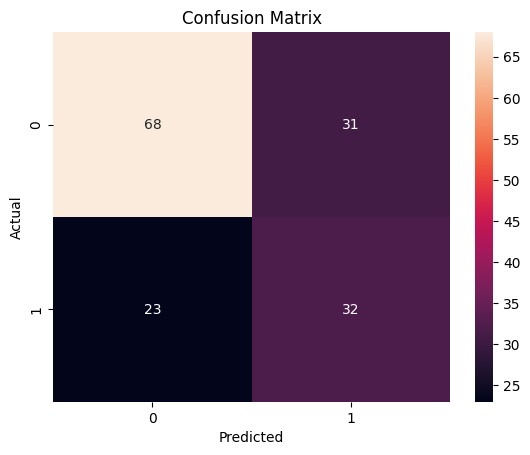

In [ ]:
import matplotlib.pyplot as plt
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True)
plt.title("Actual vs Predicted Confusion Matrix for Decision Tree")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [ ]:
from sklearn.tree import plot_tree

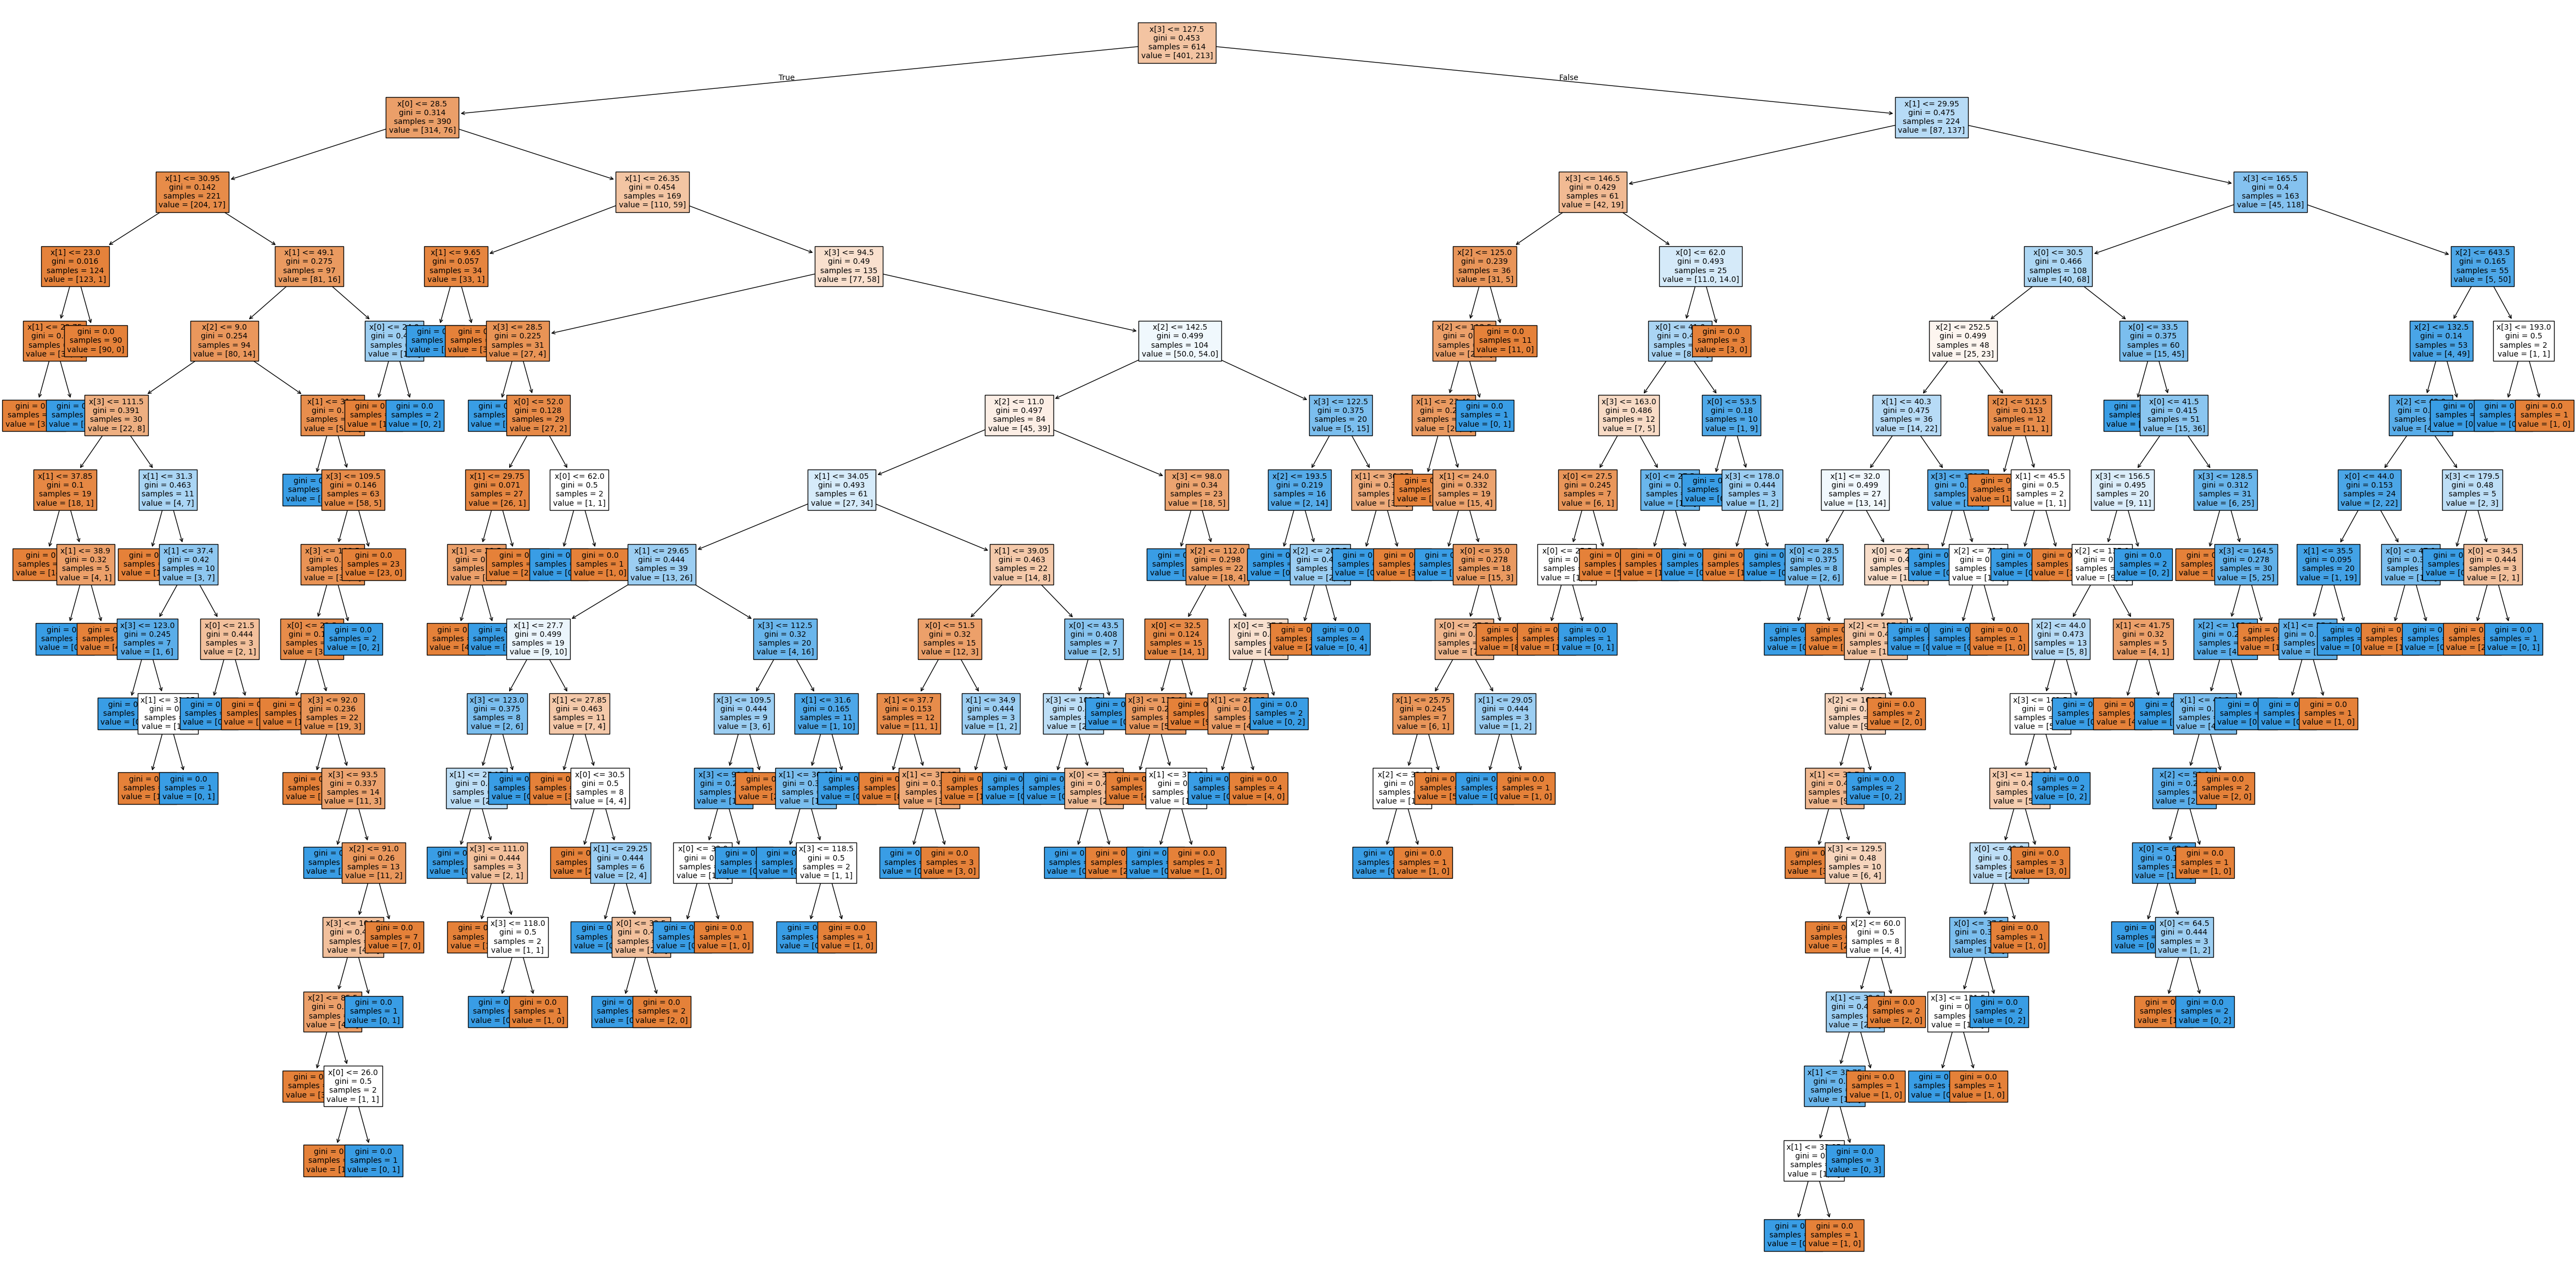

In [ ]:
plt.figure(figsize = (60,30))
plot_tree(Dct, fontsize = 10, filled=True)
plt.savefig("DecisionTree.pdf")
plt.show()
